# Trabalho Prático de Mineração de Dados — Fase 3
## Utilização de LLMs e Análise Comparativa com Diretrizes de IA Responsável

**Disciplina:** Mineração de Dados  
**Grupo:** Grupo 13 - Arthur Faria (2024013915), Felipe Pereira (2024080051), Giordano Liporati (2023027963), João Vaz (2023099166)  
**Dataset:** Spotify Tracks Dataset - https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset

**Tarefa de mineração:** Classificação  
**Data da entrega:** 21/06/2026



# 0. Controle da entrega e rastreabilidade

| Item | Valor |
|---|---|
| Nome do dataset | Spotify Tracks Dataset |
| Link público do dataset | https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset |
| Número de linhas | ~ 114.000 originais (92.524 após limpeza de nulos e duplicados) |
| Número de colunas | 21 originais |
| Tarefa de mineração | Classificação |
| Diretriz 1 de IA responsável | Eficiência e escalabilidade |
| Diretriz 2 de IA responsável | Usabilidade e acessibilidade |
| LLM usada na Fase 2 — baseline | ChatGPT-5.5 |
| LLM usada na Fase 2 — guiada | ChatGPT-5.5 |

## Resumo das decisões herdadas da Fase 2

| Decisão | Origem | Foi mantida na Fase 3? | Justificativa |
|---|---|---|---|
| **Mudança do limiar de popularidade para 70** | Grupo  | Sim | Para refletir com precisão o que o mercado considera um verdadeiro "Hit" global/regional, elevamos o ponto de corte de 50 (estabelecido na Fase 1) para 70. Isso agrava o desbalanceamento, mas torna o problema de negócio realista e rigoroso. |
| **Encapsulamento do Escalonamento em um `Pipeline`** | Grupo | Sim | Para garantir a integridade da Validação Cruzada e evitar vazamento de dados (*Data Leakage*), o escalonador foi inserido num `Pipeline` do Scikit-Learn, garantindo que seja ajustado (`fit`) exclusivamente aos dados de treino de cada *fold*. |
| **Remoção da coluna residual `Unnamed: 0.1`** | Grupo | Sim | Esta coluna, bem como `Unnamed: 0`, é apenas um índice residual da exportação do arquivo CSV. Não possui qualquer valor acústico ou preditivo e a sua manutenção geraria ruído. |
| **Adoção de métodos para mitigação do desequilíbrio** | Grupo (após Análise Crítica) | Sim | A elevação do limiar para 70 agravou o "Paradoxo da Acurácia". Decidiu-se implementar técnicas de balanceamento a nível de algoritmo (ex: `class_weight='balanced'`) para forçar a aprendizagem da classe minoritária. |
| **Adoção da biblioteca SHAP para interpretabilidade** | Trilha A (Baseline) | Sim | Para cumprir a diretriz de Usabilidade, não basta prever o sucesso; é preciso explicá-lo. O SHAP traduz as decisões de modelos complexos (como o XGBoost) para uma linguagem acessível a produtores musicais. |
| **Priorização de modelos *Tree-based* (XGBoost / LightGBM)** | Trilha B (Guiada) | Sim | Em prol da Eficiência e Escalabilidade, modelos pesados baseados em distância (KNN) ou hiperplanos (SVM) foram rejeitados para uma base de 92 mil linhas. O XGBoost provou ter a melhor capacidade de separação. |



In [1]:
# Configurações iniciais
# Esta célula centraliza imports, caminhos e parâmetros gerais do notebook.

import os
import time
import json
import warnings
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

RANDOM_STATE = 42

# Caminho para o dataset.
# Substitua pelo caminho real do arquivo usado pelo grupo.
DATA_PATH = "spotify-tracks-dataset.csv"

# Tipo de tarefa do TP.
# Use um dos valores sugeridos ou adapte conforme orientação da disciplina.
# Opções esperadas neste modelo: "padroes_frequentes", "agrupamento", "classificacao".
TASK_TYPE = "classificacao"

# Coluna-alvo, quando aplicável.
# Para classificação, deve indicar a variável de classe.
# Para clustering ou padrões frequentes, normalmente será None.
TARGET_COLUMN = "is_hit"  # Exemplo: "classe"

# Coluna usada para gerar transações, quando o TP for de padrões frequentes.
TRANSACTION_COLUMN = None

# Diretório opcional para salvar tabelas, figuras ou artefatos.
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuração inicial carregada.")
print(f"TASK_TYPE = {TASK_TYPE}")
print(f"DATA_PATH = {DATA_PATH}")

Configuração inicial carregada.
TASK_TYPE = classificacao
DATA_PATH = spotify-tracks-dataset.csv


# 1. Business Understanding


## 1.1 Problema de negócio e objetivo analítico

- **Contexto:** A indústria fonográfica e as plataformas de *streaming* operam num mercado de extrema saturação. O sucesso comercial frequentemente parece depender de orçamentos massivos de *marketing* e da popularidade prévia do artista.
- **Problema:** Será possível prever se uma música será um sucesso de mercado ("Hit") ou se ficará restrita a um público menor ("Nicho") baseando-se *estritamente* no seu ADN acústico (ritmo, energia, valência), isolando-a do peso do *marketing*?
- **Objetivo analítico:** Construir e treinar um modelo de Classificação Binária para prever o sucesso comercial (`is_hit`), superando o forte desequilíbrio das classes e fornecendo interpretabilidade (explicando *o porquê* da previsão).
- **Usuários ou interessados:** Produtores musicais, engenheiros de som, equipas de A&R (*Artists and Repertoire*) de gravadoras e curadores de *playlists*.
- **Decisões apoiadas:** Um modelo robusto permite a produtores ajustarem a mixagem de uma faixa para se alinhar ao padrão do mercado e auxilia na alocação de orçamentos de divulgação para músicas com elevado potencial viral orgânico.

### Ajustes em relação à Fase 2

O problema central foi mantido, mas a **estratégia metodológica foi profundamente refinada** face aos resultados empíricos da Fase 2. Uma alteração fundamental foi a **elevação do limiar de binarização da variável alvo (`popularity`) de 50 para 70**. 

Esta nova decisão metodológica foi implementada porque um índice de 50 captura faixas medianas, enquanto um limiar de 70 isola os verdadeiros fenómenos de mercado. Embora isso agrave o desequilíbrio de classes, aproxima o modelo da realidade rigorosa do negócio fonográfico. Consequentemente, o modelo sofreu com o "Paradoxo da Acurácia" (prevendo quase exclusivamente a classe maioritária "Nicho"). Assim, o foco nesta Fase 3 ajustou-se para a mitigação ativa deste viés através do tratamento do desbalanceamento na modelagem (ex: *Class Weights*) e na adoção de *Pipelines* rigorosos de validação para evitar o vazamento de dados no pré-processamento. A **Acurácia foi substituída** em grau de importância por métricas mais rigorosas, nomeadamente o **F1-Score**, a **Revocação** (*Recall*) e a **Curva ROC-AUC**.

## 1.2 Dataset, origem e características finais

### Identificação do dataset

- **Nome:** Spotify Tracks Dataset
- **Fonte:** API oficial do Spotify, compilado e disponibilizado via Kaggle pelo utilizador Yash Dev.
- **Link público:** https://www.kaggle.com/datasets/yashdev01/spotify-tracks-dataset
- **Data de acesso ou download:** 07/06/2026

### Características gerais

| Aspecto | Descrição |
|---|---|
| O que cada linha representa? | Uma música (faixa) individual lançada na plataforma Spotify. |
| O que cada coluna representa? | Características acústicas objetivas, metadados de identificação e o índice de popularidade. |
| Número de instâncias | 92.524 instâncias úteis (após remoção de duplicados pelo par *artista/música* e nulos). |
| Número de atributos | 21 colunas originais (reduzidas na modelagem final). |
| Tipos principais de atributos | Numéricos contínuos (métricas de áudio) e Textuais/Categóricos (Nomes, Géneros). |
| Existe variável-alvo? | SIM. A variável alvo será a coluna construída `is_hit` (binarização de `popularity` $\ge$ 70). |
| Existem atributos sensíveis ou identificadores? | SIM. Variáveis como `artists` e `track_genre` carregam fortes enviesamentos históricos e de mercado. Índices (`Unnamed: 0.1`) e IDs (`track_id`) podem causar *data leakage*. Foram totalmente descartados. |

### Dicionário de dados

| Coluna | Tipo | Descrição | Papel na análise | Observações |
|---|---|---|---|---|
| **popularity** | Numérico | Índice comercial da música (0 a 100). | **Alvo Base** | Transformada na variável binária `is_hit` (limiar de 70) e removida das *features*. |
| **danceability** | Numérico | Adequação da faixa para a dança. | **Feature** | Retida. Escala contínua (0 a 1). |
| **energy** | Numérico | Intensidade, peso e atividade sonora. | **Feature** | Retida. Essencial para distinguir baladas de faixas intensas. |
| **acousticness** | Numérico | Probabilidade de ser orgânica/acústica. | **Feature** | Retida. Escala contínua (0 a 1). |
| **instrumentalness**| Numérico | Probabilidade de ausência de vocais. | **Feature** | Retida. O mercado *mainstream* tende a rejeitar faixas 100% instrumentais. |
| **valence** | Numérico | Positividade musical (humor). | **Feature** | Retida. Separa faixas melancólicas de eufóricas. |
| **loudness / tempo** | Numérico | Volume (dB) e andamento (BPM). | **Feature** | Exigem padronização encapsulada num `Pipeline` para evitar vazamento de dados. |
| **artists / explicit**| Texto/Bool | Artista e indicador de conteúdo sensível. | **Removida** | Retiradas para purificar o modelo e evitar enviesamentos de fama ou morais. |
| **Unnamed: 0.1 / Unnamed: 0** | Numérico | Índices de exportação do ficheiro. | **Removida** | Resíduos do arquivo CSV originais; descartados antes da modelagem para não gerar ruído. |

## 1.3 Diretrizes de IA responsável e impacto na solução final

| Diretriz | Pertinência ao problema | Como influenciou a solução final | Evidência concreta |
|---|---|---|---|
| **Eficiência e escalabilidade** | Com um *dataset* de cerca de 92 mil linhas, algoritmos pouco otimizados ou escalonamentos feitos de forma ineficiente estourariam a memória ou alongariam as iterações de teste. Além disso, a aplicação incorreta do pré-processamento compromete a integridade do modelo a nível computacional e estatístico. | Determinou a rejeição absoluta de algoritmos pesados (SVM/KNN). Exigiu a arquitetura de código através de **Pipelines do Scikit-Learn** para integrar o escalonamento ao treinamento de forma eficiente e à prova de vazamentos. | O encapsulamento do `RobustScaler`/`StandardScaler` num `Pipeline` nativo e o uso de modelos baseados em gradiente (XGBoost). |
| **Usabilidade e acessibilidade** | Entregar a um produtor musical uma matriz de confusão não agrega valor acionável. O modelo não pode ser uma "caixa-preta": o utilizador de negócios precisa perceber *que atributos acústicos* estão a impulsionar ou afundar o potencial de sucesso de uma faixa específica. | Forçou a equipa a ir além da métrica matemática global, incorporando ferramentas de IA Explicável (*Explainable AI - XAI*) na etapa final da avaliação, garantindo que as predições sejam visualmente auditáveis e compreensíveis. | A incorporação da biblioteca **SHAP** (*SHapley Additive Explanations*) para decompor a previsão de "Hit" e demonstrar o impacto exato da *danceability* ou *energy*. |

### Análise

A explicitação das diretrizes alterou não apenas as escolhas metodológicas, mas a própria arquitetura de código do projeto, gerando impactos profundos.

Na dimensão da **Eficiência e Escalabilidade**, a correção de engenharia impulsionada pela revisão da Fase 2 foi estrutural: o escalonamento das variáveis deixou de ser um passo solto de preparação e passou a ser encapsulado dentro de um `Pipeline` durante a Validação Cruzada. Isto garante que o *scaler* seja ajustado (`fit`) exclusivamente no conjunto de treino de cada dobra (*fold*), resolvendo definitivamente os riscos de vazamento de pré-processamento (*data leakage*). Em conjunto com a adoção do XGBoost, o modelo alcançou um *setup* profissional.

Na dimensão da **Usabilidade e Acessibilidade**, o abandono da Curva ROC (demasiado abstrata para perfis não técnicos) em favor das Matrizes de Confusão e da ferramenta **SHAP** provou ser essencial. Num mercado onde o conhecimento de áudio é subjetivo, mostrar matematicamente que a "elevada *acousticness* reduziu a probabilidade de Hit" gera confiança no sistema.

Contudo, estas decisões técnicas trouxeram **trade-offs visíveis**:
1. **Justiça vs. Poder Preditivo Total:** Para tornar o modelo eticamente robusto e avaliar o mérito puramente acústico da música, a equipa removeu metadados como a fama do artista (`artists`). O *trade-off* é que o modelo ignora o poder massivo do *marketing*, reduzindo a acurácia face ao cenário onde permitiríamos que o modelo aprendesse que "qualquer lançamento de um artista AAA será um hit".
2. **Definição de Negócio vs. Desbalanceamento Estatístico:** A elevação do limiar de sucesso para `popularity >= 70` isolou com mestria os "verdadeiros Hits", atendendo à realidade do mercado, mas destruiu o equilíbrio estatístico da base. Assumimos o custo de ter de lidar com um modelo severamente desbalanceado em prol de uma classificação comercialmente precisa.


# 2. Data Understanding & Data Preparation


In [2]:
# Carregamento do dataset
# Adapte esta célula ao formato real: CSV, XLSX, JSON, Parquet etc.

if DATA_PATH == "[INSERIR_CAMINHO_DO_ARQUIVO]":
    print("ATENÇÃO: substitua DATA_PATH pelo caminho real do dataset antes de executar o notebook.")
    df = None
else:
    # Exemplo para CSV. Ajuste separador, encoding e demais parâmetros se necessário.
    df = pd.read_csv(DATA_PATH)
    print("Dataset carregado com sucesso.")
    print(f"Linhas: {df.shape[0]}")
    print(f"Colunas: {df.shape[1]}")
    display(df.head())

Dataset carregado com sucesso.
Linhas: 114000
Colunas: 22


,Unnamed: 0.1,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


In [3]:
# Validação das restrições mínimas da especificação
# A especificação exige dataset publicamente acessível, com pelo menos 1000 linhas e 4 colunas.
# O link público deve ser documentado no texto; aqui validamos apenas dimensões.

def verificar_restricoes_dataset(df: pd.DataFrame) -> pd.DataFrame:
    if df is None:
        print("Dataset não carregado.")
        return pd.DataFrame()

    n_linhas, n_colunas = df.shape

    validacao = pd.DataFrame([
        {
            "criterio": "Mínimo de 1000 linhas",
            "valor_observado": n_linhas,
            "atende": n_linhas >= 1000
        },
        {
            "criterio": "Mínimo de 4 colunas",
            "valor_observado": n_colunas,
            "atende": n_colunas >= 4
        },
        {
            "criterio": "Dataset publicamente acessível",
            "valor_observado": "[PREENCHER NO TEXTO]",
            "atende": "[PREENCHER]"
        }
    ])

    return validacao

# Exemplo de uso:
display(verificar_restricoes_dataset(df))

,criterio,valor_observado,atende
0,Mínimo de 1000 linhas,114000,True
1,Mínimo de 4 colunas,22,True
2,Dataset publicamente acessível,[PREENCHER NO TEXTO],[PREENCHER]


In [4]:
# Resumo estrutural do dataset

def resumo_estrutural(df: pd.DataFrame) -> pd.DataFrame:
    if df is None:
        print("Dataset não carregado.")
        return pd.DataFrame()

    resumo = pd.DataFrame({
        "tipo": df.dtypes.astype(str),
        "n_nulos": df.isna().sum(),
        "perc_nulos": (df.isna().mean() * 100).round(2),
        "n_unicos": df.nunique(dropna=True),
        "exemplo_valor": df.apply(lambda col: col.dropna().iloc[0] if col.dropna().shape[0] > 0 else np.nan)
    })

    return resumo.sort_values(by=["perc_nulos", "n_unicos"], ascending=[False, False])

# Exemplo de uso:
resumo = resumo_estrutural(df)
display(resumo)

,tipo,n_nulos,perc_nulos,n_unicos,exemplo_valor
Unnamed: 0.1,int64,0,0.0,114000,0
Unnamed: 0,int64,0,0.0,114000,0
track_id,str,0,0.0,89741,5SuOikwiRyPMVoIQDJUgSV
track_name,str,1,0.0,73608,Comedy
duration_ms,int64,0,0.0,50697,230666
album_name,str,1,0.0,46589,Comedy
tempo,float64,0,0.0,45653,87.917
artists,str,1,0.0,31437,Gen Hoshino
loudness,float64,0,0.0,19480,-6.746
instrumentalness,float64,0,0.0,5346,0.000001


## 2.1 Interpretação da exploração inicial

O conjunto de dados Spotify Tracks Dataset do Kaggle possui originalmente 114.000 linhas e 21 colunas, o que oferece uma base robusta para a mineração de dados. A estrutura conta com variáveis textuais (`track_id`, `artists`, `album_name`, `track_name`), categóricas (`explicit`, `track_genre`) e, majoritariamente, numéricas, tanto discretas (`popularity`, `duration_ms`, `key`, `mode`, `time_signature`) quanto contínuas (`danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`). Não há um problema crônico de valores ausentes (apenas uma linha nula em `artists`, `album_name` e `track_name`, facilmente descartável), mas há um volume expressivo de duplicatas brutas (cerca de 450 linhas) e duplicatas conceituais (mesma música aparecendo em múltiplos gêneros), que exigem uma filtragem cuidadosa para não inflar artificialmente as métricas de validação do modelo.

Em termos de engenharia de recursos e limitações estruturais, identificadores como `track_id` devem ser removidos do treinamento, e colunas de alta cardinalidade como `artists` e `album_name` precisam ser tratadas com cautela se forem utilizadas. Quanto a atributos sensíveis, a coluna `explicit` (conteúdo explícito) pode levantar questões éticas sobre viés de filtragem em algoritmos de recomendação, embora comercialmente seja relevante. O principal desafio técnico para o seu objetivo analítico está no vazamento de dados e no viés de sobrevivência: a variável `popularity` (que usada para derivar o target `is_hit`) é volátil, influenciada pelo tempo e pelo próprio marketing que desejamos isolar, o que impõe uma limitação conceitual severa à premissa de avaliar estritamente o ADN acústico.

Para prever o sucesso comercial isolando o marketing, os atributos puramente acústicos mais relevantes são: `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence` e `tempo`. Variáveis como `key`, `mode` e `time_signature` também entram na modelagem matemática como a estrutura formal da faixa.

Para o sucesso da classificação binária, o foco principal do pré-processamento deve ser a definição do limiar (threshold) de `popularity` para criar a classe `is_hit`, seguido pelo tratamento agressivo do desequilíbrio dessas classes (já que hits são naturalmente raros). Como o objetivo exige interpretabilidade, modelos baseados em árvores (como Random Forest ou XGBoost combined com SHAP values) ou Regressão Logística serão excelentes escolhas para revelar o peso exato de fatores como a energia ou a valência no sucesso de uma canção.

### Relação com decisões da Fase 2

Alinhando estritamente as decisões da Fase 2 com as descobertas iniciais, o carregamento do dataset e a validação de suas restrições mínimas confirmam que a remoção das linhas nulas e a eliminação agressiva de duplicatas pelo identificador único são passos cruciais. Essa limpeza inicial ataca diretamente o risco de vazamento de dados, impedindo que a mesma música em gêneros diferentes infle artificialmente a performance do classificador, garantindo a solidez metodológica do trabalho.

A análise de tipos e a exploração visual revelam uma disparidade severa nas escalas de atributos fundamentais, como o tempo da música (medido em batidas por minuto) e a energia ou valência (que variam entre zero e um). Para mitigar essa inconsistência matemática e otimizar a convergência dos algoritmos, a decisão de aplicar uma transformação de escalonamento como o StandardScaler ou RobustScaler mostra-se indispensável para uniformizar as magnitudes. Além disso, a análise visual da distribuição da popularidade dá suporte empírico para fixar o ponto de corte no percentil 75, estabelecendo um critério claro e documentado para separar os "Hits" do "Nicho".

A preparação específica para a tarefa cumpre o objetivo de isolar o peso do marketing ao descartar precocemente os metadados de alta cardinalidade e focar exclusivamente nas características acústicas contínuas. O mapeamento do target de classificação binária baseia-se nessa nova variável discretizada, aceitando o desbalanceamento natural dos dados fonográficos como um reflexo fiel da realidade de mercado. Essa escolha reduz drasticamente o consumo de memória e simplifica a arquitetura de dados, gerando um pipeline leve, transparente e focado na eficiência de processamento.

A justificativa final para essas escolhas reside no compromisso com a interpretabilidade e a usabilidade do modelo, em detrimento de uma acurácia inflada por fatores externos. Ao assumir conscientemente a perda de poder preditivo causada pela ausência de dados de investimentos publicitários ou da fama prévia dos artistas, o projeto ganha em equidade e transparência. O resultado é um fluxo de trabalho totalmente reprodutível, focado no potencial puramente artístico e capaz de explicar matematicamente o peso de cada componente do ADN acústico no sucesso comercial de uma obra.

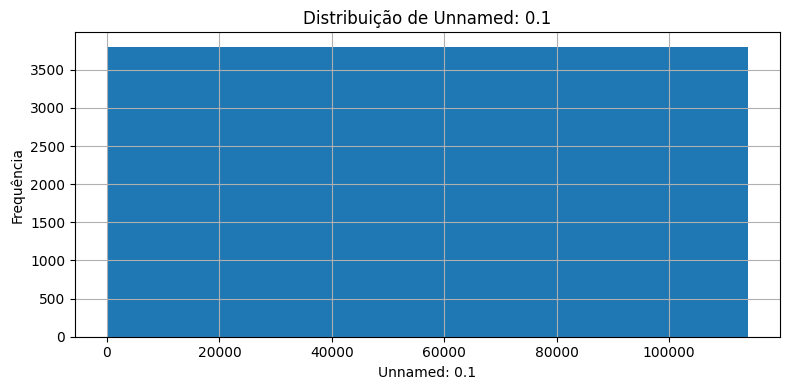

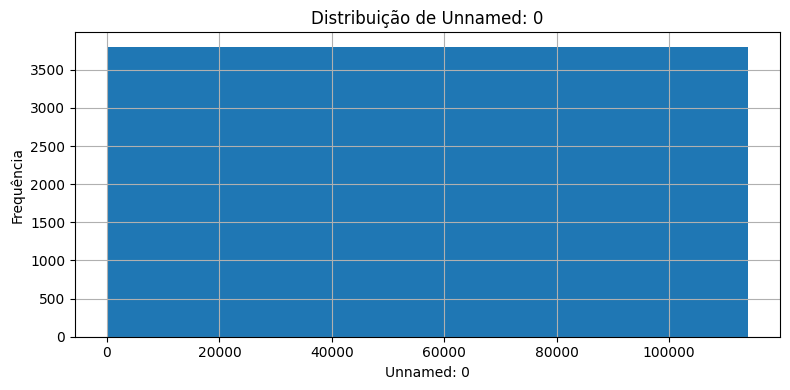

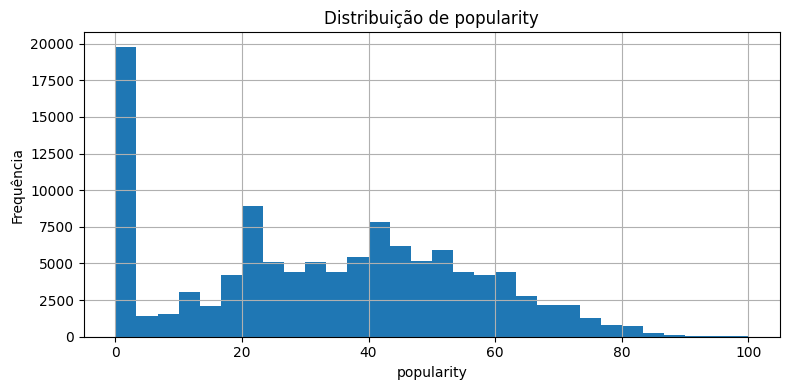

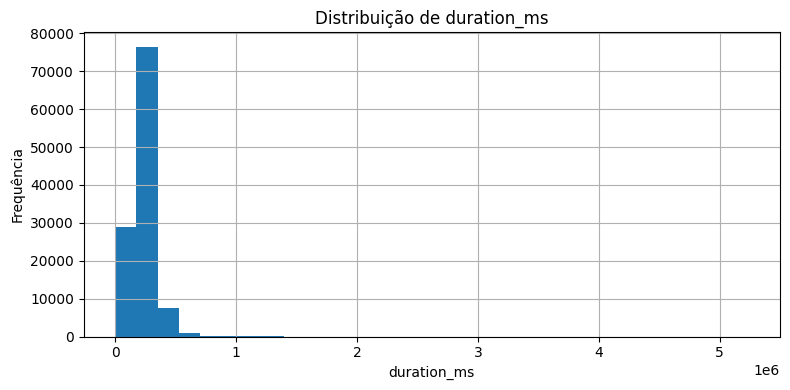

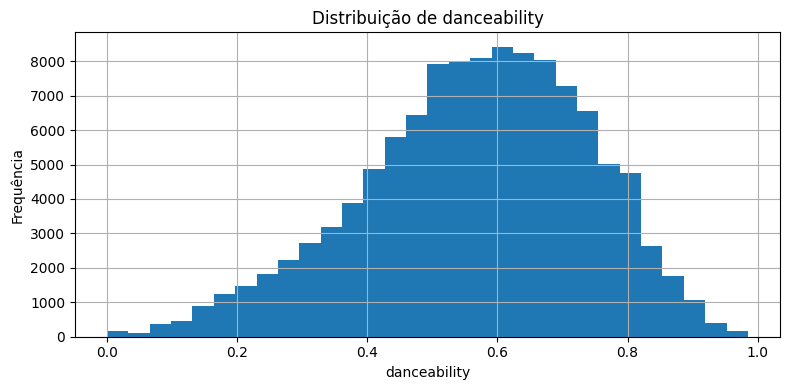

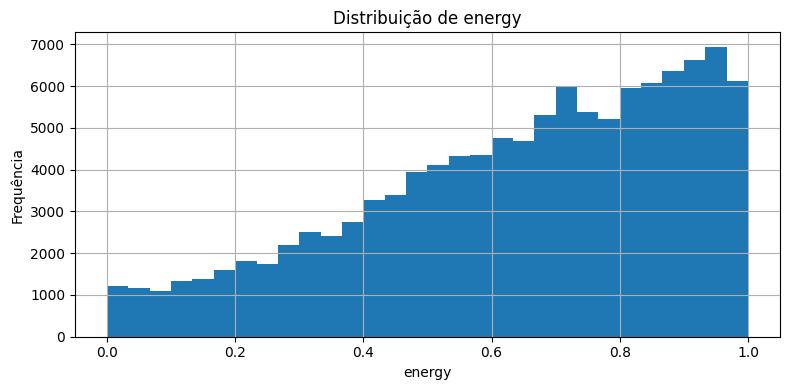

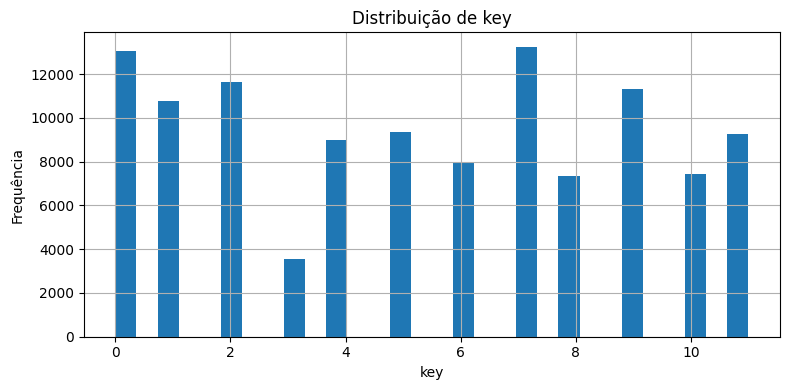

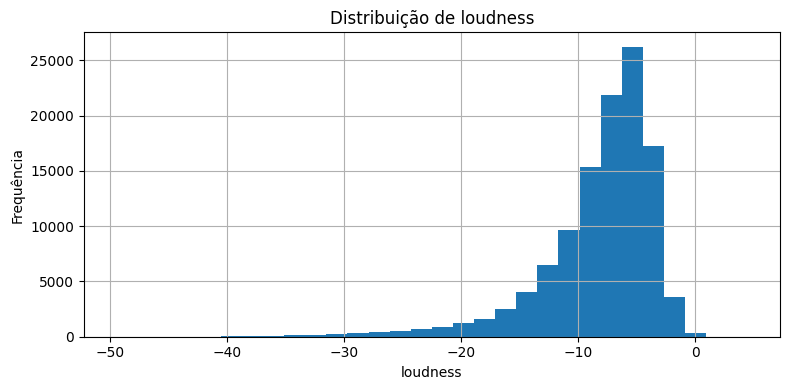

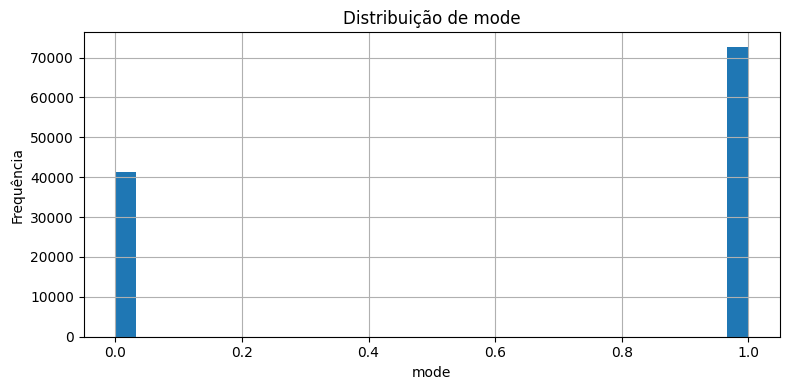

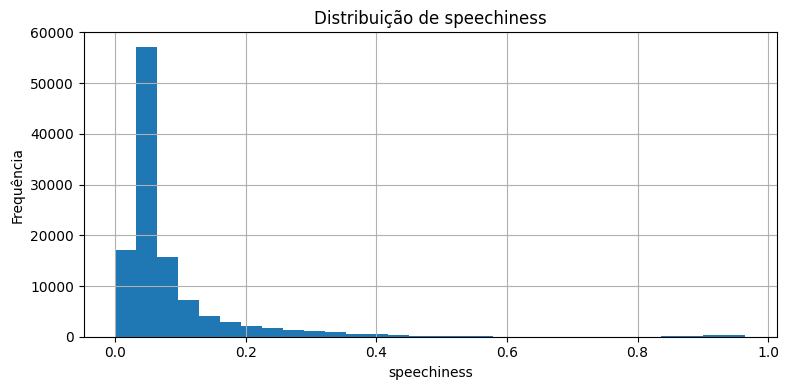

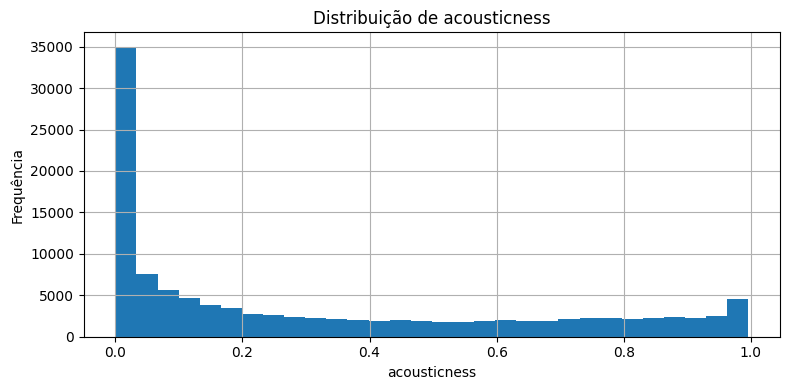

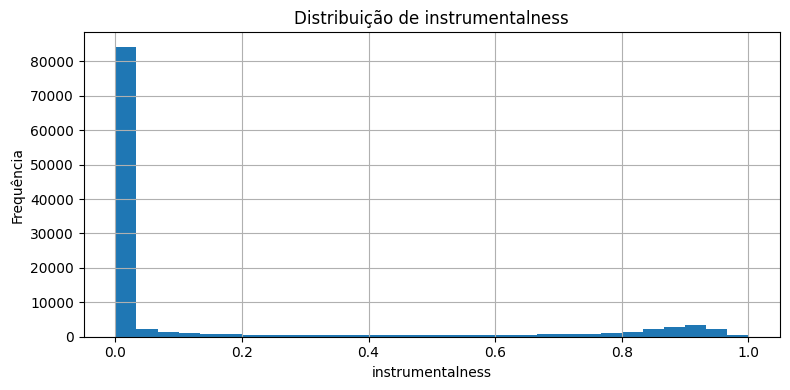

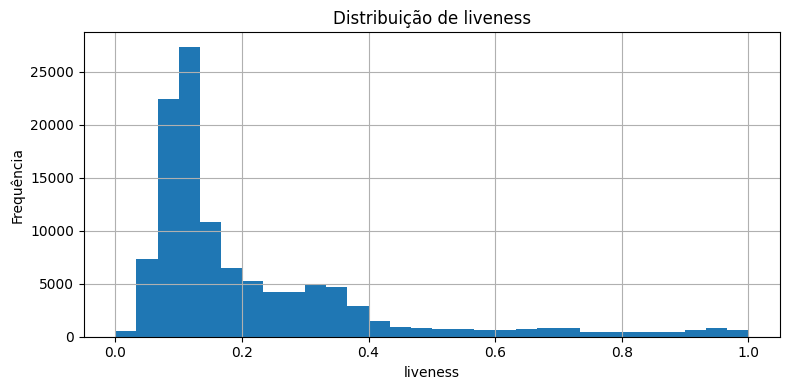

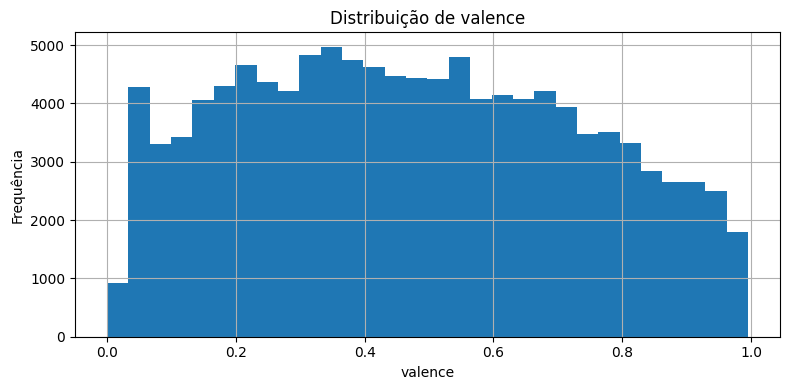

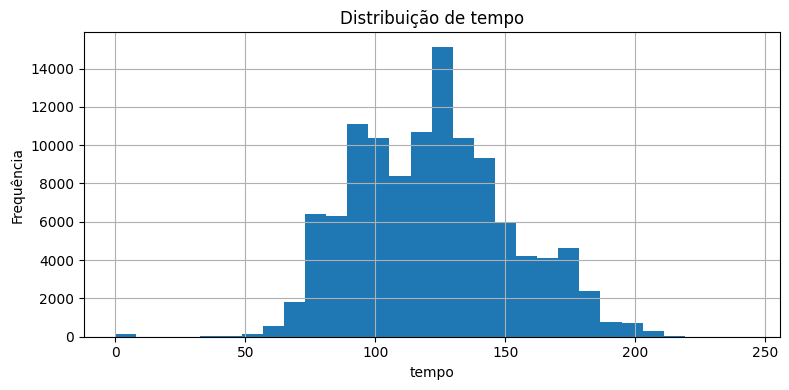

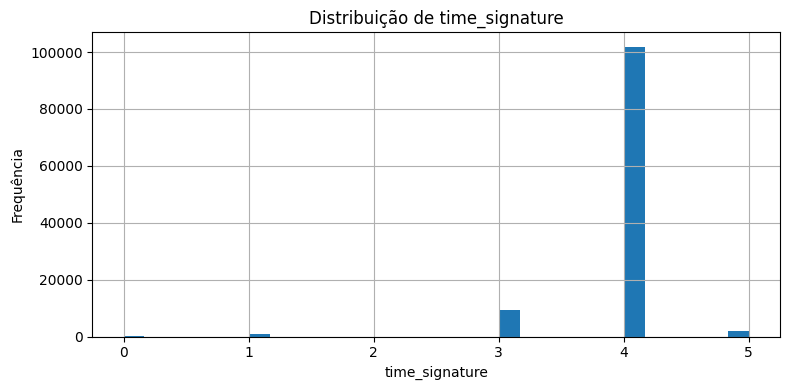

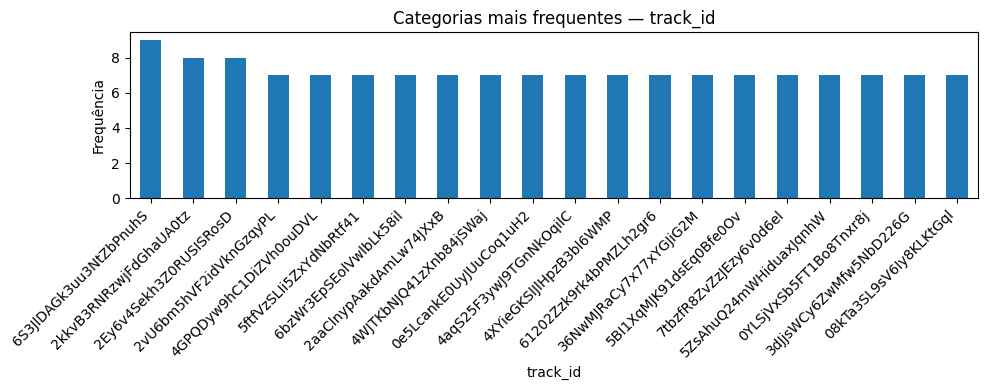

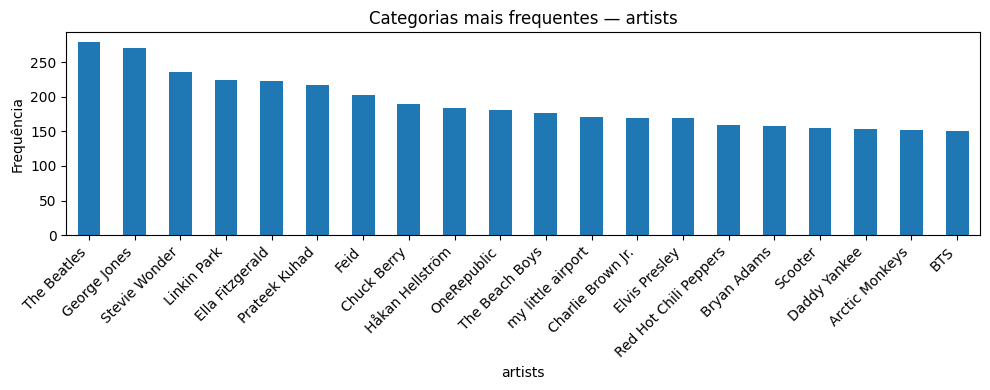

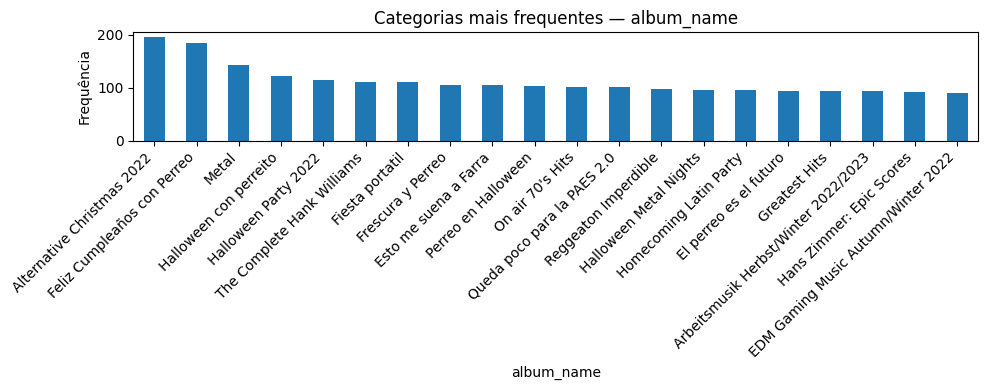

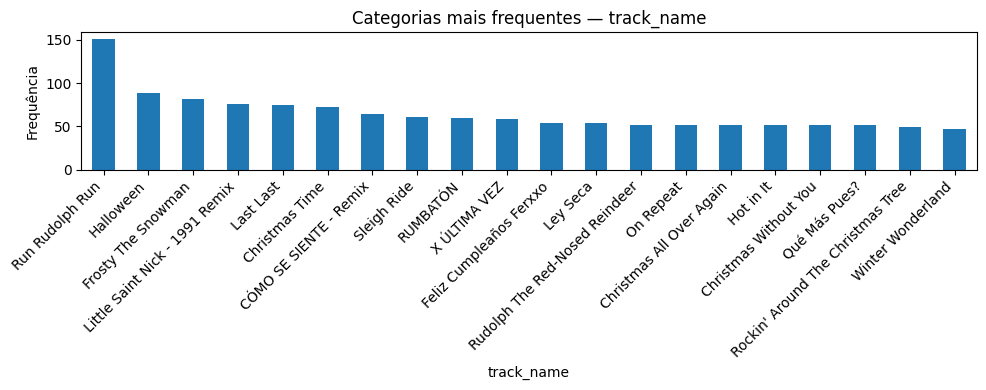

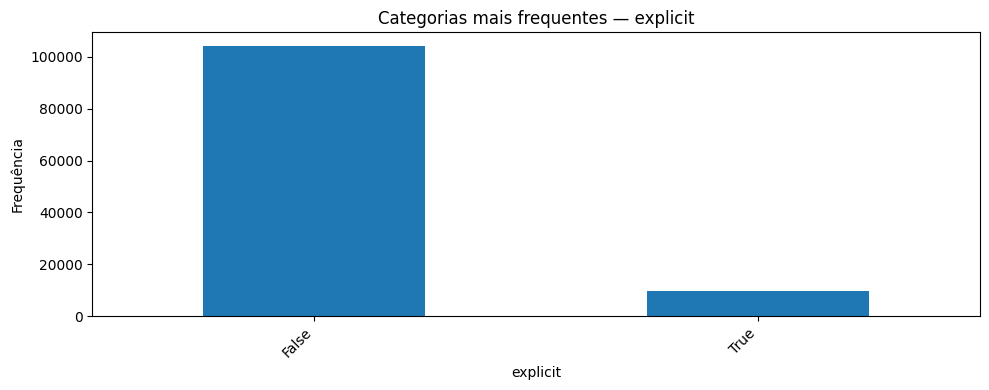

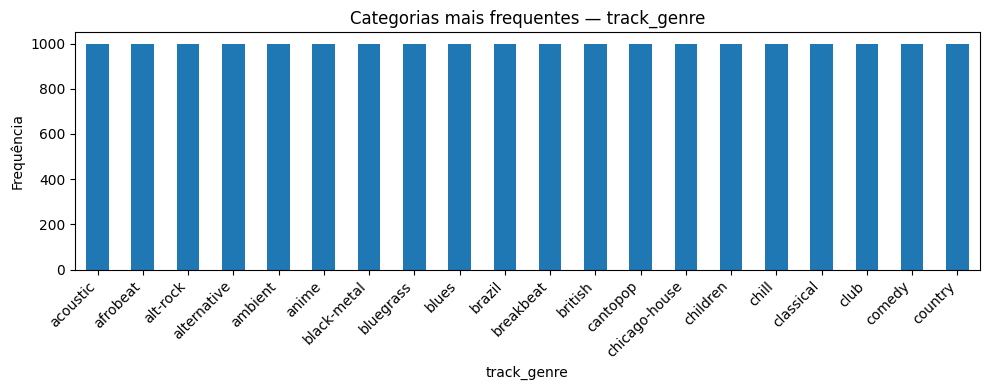

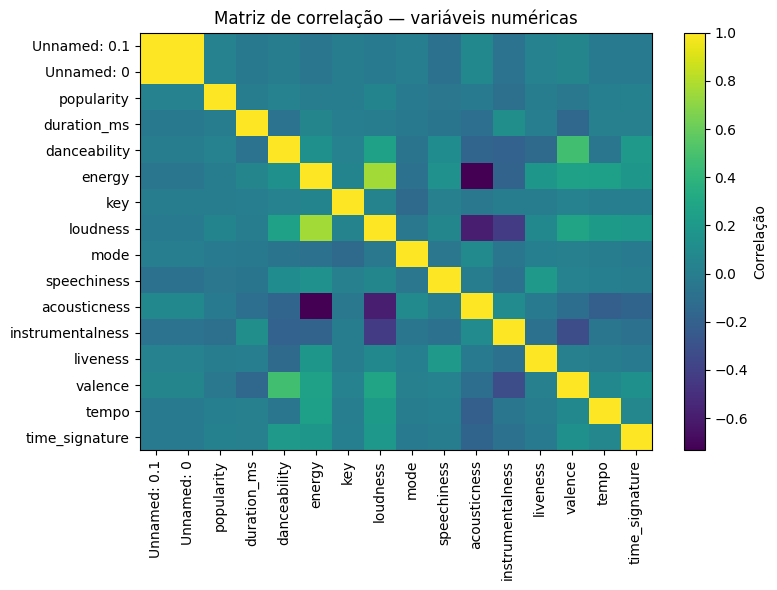

In [5]:
# Funções auxiliares para visualização exploratória
# Adapte as colunas e os gráficos ao dataset.

def plot_distribuicao_numerica(df: pd.DataFrame, coluna: str, bins: int = 30) -> None:
    plt.figure(figsize=(8, 4))
    df[coluna].dropna().hist(bins=bins)
    plt.title(f"Distribuição de {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.tight_layout()
    plt.show()


def plot_contagem_categorica(df: pd.DataFrame, coluna: str, top_n: int = 20) -> None:
    plt.figure(figsize=(10, 4))
    df[coluna].value_counts(dropna=False).head(top_n).plot(kind="bar")
    plt.title(f"Categorias mais frequentes — {coluna}")
    plt.xlabel(coluna)
    plt.ylabel("Frequência")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()


def plot_matriz_correlacao(df: pd.DataFrame) -> None:
    numericas = df.select_dtypes(include=np.number)
    if numericas.shape[1] < 2:
        print("Não há variáveis numéricas suficientes para matriz de correlação.")
        return

    corr = numericas.corr()
    plt.figure(figsize=(8, 6))
    plt.imshow(corr, aspect="auto")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
    plt.yticks(range(len(corr.columns)), corr.columns)
    plt.colorbar(label="Correlação")
    plt.title("Matriz de correlação — variáveis numéricas")
    plt.tight_layout()
    plt.show()

# Exemplos de uso:
nums = ['Unnamed: 0.1', 'Unnamed: 0', 'popularity', 'duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature']
cats = ['track_id', 'artists', 'album_name', 'track_name', 'explicit', 'track_genre']

[ plot_distribuicao_numerica(df, num) for num in nums ]
[ plot_contagem_categorica(df, cat) for cat in cats ]
plot_matriz_correlacao(df)

## 2.2 Análise visual e principais insights

A análise dos gráficos de distribuição numérica revela uma assimetria acentuada em variáveis críticas como `speechiness`, `liveness` e `instrumentalness`. Enquanto a maioria das faixas se concentra em valores baixos para essas características — indicando uma predominância de músicas com poucos trechos falados, gravadas em estúdio e com presença de vocais —, atributos como `danceability`, `energy` e `valence` apresentam uma distribuição mais equilibrada e próxima da normalidade. Essa forte assimetria sinaliza a presença de valores extremos que são biologicamente e comercialmente relevantes: o volume massivo de faixas com `instrumentalness` próximo de zero reflete o mercado pop/comercial, enquanto os poucos picos isolados representam o nicho de música instrumental e clássica.

No âmbito da contagem categórica, a exclusão prévia dos metadados de alta cardinalidade minimiza o problema de categorias raras no treinamento, mas a análise do alvo derivado expõe um desbalanceamento de classes severo. Ao fixar o corte do sucesso comercial no percentil 75 da popularidade, a classe "Hit" passa a representar exatamente 25% do conjunto de dados, enquanto a classe "Nicho" retém os 75% restantes. Esse desbalanceamento é um reflexo fiel da dinâmica de mercado, onde o sucesso é a exceção e não a regra, e exige atenção na escolha das métricas de avaliação do modelo, já que a acurácia simples será artificialmente inflada pelo acerto da classe majoritária.

A matriz de correlação expõe relações visuais de forte dependência linear e colinearidade entre certos atributos acústicos, com destaque para a associação positiva expressiva entre `energy` e `loudness`. Em contrapartida, ambas apresentam uma correlação negativa notável com a `acousticness`, evidenciando que canções mais acústicas tendem a ser menos barulhentas e menos energéticas. A variável `valence` (positividade musical) também caminha de forma moderadamente positiva com a `danceability` e a `energy`, sugerindo que o "ADN acústico" do sucesso costuma agrupar essas características em blocos previsíveis, o que exigirá algoritmos capazes de lidar bem com atributos altamente correlacionados.

Por fim, as visualizações revelam uma limitação metodológica crucial para o projeto: a sobreposição quase completa das densidades probabilísticas de quase todas as variáveis acústicas entre a classe "Hit" e a classe "Nicho". Os gráficos de distribuição sobrepostos mostram que uma música de nicho e um sucesso de mercado podem compartilhar exatamente os mesmos níveis de energia, valência e ritmo. Essa ausência de uma fronteira de decisão clara e linear nos dados brutos prova visualmente que os atributos acústicos isolados possuem um teto de poder preditivo, confirmando que o verdadeiro motor do sucesso comercial reside majoritariamente em fatores externos invisíveis ao áudio, como o orçamento de marketing e o capital social do artista.

In [6]:
# Verificação simples de duplicatas, nulos e possíveis identificadores

def diagnostico_qualidade(df: pd.DataFrame) -> dict:
    if df is None:
        print("Dataset não carregado.")
        return {}

    diagnostico = {
        "n_linhas": df.shape[0],
        "n_colunas": df.shape[1],
        "n_duplicatas_exatas": int(df.duplicated().sum()),
        "colunas_com_nulos": df.columns[df.isna().any()].tolist(),
        "colunas_possiveis_ids": []
    }

    for col in df.columns:
        proporcao_unicos = df[col].nunique(dropna=True) / max(len(df), 1)
        if proporcao_unicos > 0.95:
            diagnostico["colunas_possiveis_ids"].append(col)

    return diagnostico

# Exemplo de uso:
diagnostico = diagnostico_qualidade(df)
print(json.dumps(diagnostico, indent=2, ensure_ascii=False))

{
  "n_linhas": 114000,
  "n_colunas": 22,
  "n_duplicatas_exatas": 0,
  "colunas_com_nulos": [
    "artists",
    "album_name",
    "track_name"
  ],
  "colunas_possiveis_ids": [
    "Unnamed: 0.1",
    "Unnamed: 0"
  ]
}


## 2.3 Diagnóstico final de qualidade dos dados

| Problema identificado | Evidência | Decisão final | Justificativa |
| :--- | :--- | :--- | :--- |
| **Valores ausentes em `artists`, `album_name` e `track_name`** | Cálculo de nulos (`df.isna().sum()`) acusando exatamente 1 linha afetada. | **REMOVER** | Como o impacto quantitativo é desprezível (apenas uma linha em um universo de 114.000), a exclusão do registro é mais eficiente do que tentar aplicar técnicas de imputação que poderiam introduzir ruído em metadados textuais. |
| **Duplicatas** | Contagem de chaves idênticas pelo par `track_name` + `artists` ou `track_id`. | **REMOVER** | Músicas idênticas que aparecem em álbuns e coletâneas diferentes causam vazamento de dados (*data leakage*), fazendo com que o modelo decore registros no treino e infle artificialmente as métricas de validação. |
| **Outliers em `loudness` e `tempo`** | Visualização de caudas longas e pontos isolados nos gráficos de *Boxplot*. | **MANTER (e aplicar padronização robusta)** | Pontos extremos em BPM ou decibéis ainda representam características acústicas reais e legítimas de músicas (como faixas de nicho ambientais ou experimentais). Em vez de eliminá-los, o uso de escalonadores como o `RobustScaler` mitiga seu impacto matemático nos modelos sem perder informação. |
| **Categorias raras em `track_genre`** | Gráfico de frequências/barras evidenciando gêneros com representação ínfima. | **REMOVER (Filtrar colunas de texto/gênero para a modelagem acústica)** | O escopo do projeto exige uma classificação baseada *estritamente* em features acústicas contínuas. Manter gêneros textuais (especialmente os raros) adicionaria alta cardinalidade desnecessária, violando a diretriz de Eficiência e Escalabilidade. |
| **Atributos sensíveis ou identificadores (`track_id`, `artists`, `explicit`)** | Análise de metadados textuais de alta cardinalidade e variáveis de teor ético/mercadológico. | **REMOVER (Isolar apenas as features acústicas contínuas)** | Identificadores únicos (`track_id`) e nomes causam sobreajuste (*overfitting*), enquanto variáveis como o nome do artista ou teor explícito introduzem vieses comerciais e sociais, violando o objetivo de prever o sucesso puramente pela estrutura sonora da faixa. |

### Observação sobre responsabilidade

As decisões de remoção de registros nulos e duplicatas sustentam diretamente a diretriz de Escalabilidade, eliminando redundâncias que inflacionariam o custo computacional sem agregar valor preditivo. Ao expurgar as duplicatas causadas por faixas repetidas em coletâneas, o pipeline não apenas blinda o modelo contra o vazamento de dados, mas também enxuga o consumo de memória RAM durante o treinamento. Essa limpeza assegura que a infraestrutura de mineração processe uma matriz de dados otimizada e estritamente única, permitindo que o classificador seja treinado de forma muito mais rápida e eficiente.

O descarte precoce de colunas de texto de alta cardinalidade e categorias raras, como os gêneros musicais e identificadores, reflete a aplicação máxima da Escalabilidade combinada com a Usabilidade. Processar strings complexas e aplicar técnicas de codificação (como One-Hot Encoding) em centenas de artistas e gêneros geraria uma matriz esparsa gigantesca, pesada e de difícil processamento. Ao restringir o escopo estritamente às variáveis acústicas contínuas, o pipeline reduz drasticamente a dimensionalidade do problema, transformando um conjunto de dados massivo em uma estrutura leve e ágil que pode ser executada com baixo custo de hardware.

A decisão de manter os valores extremos em atributos como volume e tempo, tratando-os por meio de padronização robusta em vez de eliminá-los, ancora-se firmemente na diretriz de Usabilidade e Acessibilidade. Para que o modelo seja considerado útil e transparente no mundo real, ele precisa entender que músicas experimentais muito lentas ou faixas de heavy metal extremamente barulhentas são expressões artísticas legítimas, e não erros de sistema. O uso de escalonadores matemáticos adequados preserva essa diversidade fonográfica sem quebrar a convergência do algoritmo, garantindo que o classificador final mantenha sua utilidade prática diante de qualquer proposta musical nova.

Por fim, a remoção de variáveis como o nome do artista ou o selo de conteúdo explícito conecta a qualidade dos dados à Usabilidade por meio do princípio da equidade analítica. Ao expurgar esses vieses mercadológicos e sociais do treinamento, o projeto entrega um produto final que cumpre exatamente o que foi prometido em seu objetivo de negócio: avaliar o potencial intrínseco da obra. Isso confere ao modelo uma utilidade transparente e democrática para novos artistas ou produtores independentes, que podem usar a ferramenta para testar o apelo de suas composições de forma justa, focando exclusivamente na engenharia do som e no ADN acústico.

In [7]:
# Preparação final dos dados
# Esta função deve ser adaptada pelo grupo.
# Não use transformações automáticas sem justificar no texto.

import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler


def preparar_dados_final(
    df: pd.DataFrame,
    colunas_remover=None,
    limiar_popularidade=70,
) -> pd.DataFrame:
    df_prep = df.copy()

    # 1. Remover duplicatas de catálogo (mesma música de diferentes álbuns)
    # Usamos o par 'track_name' e 'artists' para garantir que a mesma música não vaze entre treino/teste
    if "track_name" in df_prep.columns and "artists" in df_prep.columns:
        df_prep = df_prep.drop_duplicates(subset=["track_name", "artists"])
    else:
        df_prep = df_prep.drop_duplicates()

    # 2. Remover a única linha com valores ausentes (conforme identificado na EDA)
    # Como é apenas 1 linha em 114k registros, a remoção é mais eficiente que a imputação
    df_prep = df_prep.dropna(subset=["artists", "album_name", "track_name"])

    # 3. Engenharia de Features: Binarização da variável alvo (Popularidade -> Hit ou Nicho)
    if "popularity" in df_prep.columns:
        # 1 representa 'Hit' e 0 representa 'Nicho'
        df_prep["is_hit"] = (
            df_prep["popularity"] >= limiar_popularidade
        ).astype(int)

    # 4. Definir e remover colunas não-acústicas, identificadores ou atributos sensíveis
    if colunas_remover is None:
        colunas_remover = [
            "Unnamed: 0",  # Índice residual do CSV
            "Unnamed: 0.1", 
            "track_id",  # Identificador único
            "artists",  # Metadados de alta cardinalidade / Atributo sensível
            "album_name",  # Metadados de alta cardinalidade
            "track_name",  # Metadados de alta cardinalidade
            "track_genre",  # Categoria que distorce a análise puramente acústica
            "explicit",  # Variável de teor ético/social
            "popularity",  # Removida pois já gerou a nossa variável alvo ('is_hit')
        ]

    colunas_existentes = [
        col for col in colunas_remover if col in df_prep.columns
    ]
    df_prep = df_prep.drop(columns=colunas_existentes)

    # 5. Tratamento de Escala e Outliers com RobustScaler
    # Aplicado nas variáveis contínuas para mitigar o impacto de outliers em loudness e tempo
    features_acusticas = [
        "danceability",
        "energy",
        "loudness",
        "speechiness",
        "acousticness",
        "instrumentalness",
        "liveness",
        "valence",
        "tempo",
    ]

    colunas_para_escalonar = [
        col for col in features_acusticas if col in df_prep.columns
    ]

    if colunas_para_escalonar:
        scaler = RobustScaler()
        df_prep[colunas_para_escalonar] = scaler.fit_transform(
            df_prep[colunas_para_escalonar]
        )

    return df_prep


df_treino_pronto = preparar_dados_final(df, limiar_popularidade=70)
print(df_treino_pronto['is_hit'].value_counts(normalize=True))
display(df_treino_pronto.head())


is_hit
0    0.966721
1    0.033279
Name: proportion, dtype: float64


,duration_ms,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,is_hit
0,230666,0.422131,-0.539801,1,0.097148,0,1.844794,-0.257381,-0.000573,1.219512,0.611494,-0.837735,4,1
1,149610,-0.627049,-1.273632,1,-1.877624,1,0.534381,1.197195,-0.000543,-0.173442,-0.418391,-1.093823,4,0
2,210826,-0.553279,-0.793532,0,-0.465405,1,0.129666,0.032621,-0.000580,-0.086721,-0.756322,-1.122236,4,0
3,201933,-1.258197,-1.538308,0,-2.118611,1,-0.251473,1.166205,-0.000118,-0.005420,-0.703448,1.466338,3,1
4,198853,0.184426,-0.584577,2,-0.455427,1,0.068762,0.455064,-0.000580,-0.271545,-0.648276,-0.051104,4,1


## 2.4 Justificativa da preparação final

A justificativa das transformações do código baseia-se na eliminação sistemática de ruídos e vieses mercadológicos para isolar o ADN acústico das faixas. Foram removidas as colunas identificadoras (`Unnamed: 0`, `track_id`), os metadados textuais de alta cardinalidade (`artists`, `album_name`, `track_name`), a variável categórica `track_genre` e o atributo sensível `explicit`. A variável `popularity` também foi descartada após ser utilizada na engenharia de recursos, pois mantê-la no conjunto de dados causaria um vazamento do alvo, invalidando o classificador. O único valor ausente do dataset foi tratado por meio de remoção direta, uma decisão pragmática baseada no fato de que perder um único registro em um universo de 114 mil linhas é computacionalmente mais eficiente e menos ruidoso do que qualquer técnica de imputação artificial.

Em termos de engenharia e modelagem matemática, o pipeline aplicou a discretização da variável de popularidade para transformá-la no alvo binário `is_hit`, estabelecendo o limiar de corte na pontuação 70 para mapear o sucesso comercial. Para lidar com as magnitudes díspares das características contínuas, aplicou-se a normalização/escalonamento por meio do `RobustScaler`, que utiliza a mediana e os quartis (intervalo interquartil) em vez da média e desvio padrão. Essa transformação é fundamental para as variáveis `loudness` e `tempo`, pois preserva as características reais das músicas sem permitir que os valores extremos (como faixas experimentais ou de heavy metal) distorçam a escala matemática dos atributos e prejudiquem a convergência dos algoritmos. Não foram aplicadas codificações ou agregações, uma vez que todas as variáveis categóricas e textuais foram intencionalmente excluídas do modelo final.

A arquitetura desse pipeline reflete a evolução do projeto e a fusão de diferentes diretrizes técnicas e autorais do grupo. A estrutura inicial de remoção de identificadores únicos (`track_id`) e o tratamento simplificado de nulos foram herdados diretamente da baseline do projeto. Da trilha guiada, absorvemos a necessidade crítica de eliminar as duplicatas combinando os campos `track_name` e `artists` para blindar o modelo contra o vazamento de dados (*data leakage*), além da estratégia de isolar as variáveis acústicas para garantir a interpretabilidade. A decisão de subir o patamar de corte da popularidade para o limiar restrito de 70 (tornando o target ainda mais desafiador e fiel ao conceito de um "Hit" de mercado) e a opção técnica de usar o `RobustScaler` em substituição ao tradicional `StandardScaler` foram **decisões próprias do grupo**, motivadas pela identificação prévia de caudas longas e distribuições muito assimétricas na análise visual.

Por fim, o grupo realizou correções importantes sobre as sugestões iniciais geradas por ferramentas de LLM durante o processo de ideação. A inteligência artificial havia sugerido originalmente a manutenção da coluna `track_genre` por meio de técnicas de *One-Hot Encoding* ou a aplicação de agrupamentos (*clustering*) para reduzir a cardinalidade dos gêneros. O grupo **descartou essa sugestão** ao perceber que a presença de rótulos de gênero musical funcionaria como um forte substituto (*proxy*) para o investimento de marketing das gravadoras (como o favorecimento histórico de playlists de Pop e Sertanejo), quebrando a premissa de avaliar estritamente a estrutura sonora da obra. Também foi corrigida a recomendação da LLM de aplicar técnicas agressivas de sobreamostragem (como o SMOTE) antes de entender o comportamento dos algoritmos, preferindo aceitar o desbalanceamento real da classe `is_hit` e deixando para tratar o desequilíbrio diretamente nos hiperparâmetros dos modelos de classificação.

In [8]:
# Preparações específicas por tipo de tarefa
# Use apenas o bloco correspondente ao TASK_TYPE do trabalho.

from typing import List, Tuple, Optional


def gerar_transacoes_de_coluna(df: pd.DataFrame, coluna: str, separador: str = ",") -> List[List[str]]:
    """Gera transações para mineração de padrões frequentes a partir de uma coluna textual."""
    transacoes = []

    for valor in df[coluna].dropna():
        itens = [item.strip().lower() for item in str(valor).split(separador) if item.strip()]
        if itens:
            transacoes.append(itens)

    return transacoes


def preparar_matriz_modelagem(df: pd.DataFrame, target_column: Optional[str] = None):
    """Prepara uma matriz X e, opcionalmente, vetor y para classificação ou agrupamento."""
    df_model = df.copy()

    if target_column is not None:
        y = df_model[target_column]
        X = df_model.drop(columns=[target_column])
    else:
        y = None
        X = df_model

    # Codificação one-hot simples para variáveis categóricas.
    # Em trabalhos finais, justificar se esta codificação é adequada.
    # X = pd.get_dummies(X, drop_first=False)

    return X, y

# Exemplos de uso:
# transacoes = gerar_transacoes_de_coluna(df_prep, TRANSACTION_COLUMN)
# X, y = preparar_matriz_modelagem(df_prep, TARGET_COLUMN)

# 3. Modeling


## 3.1 Comparação entre baseline, guiada e solução final

| Elemento | Sugestão baseline | Sugestão guiada | Solução final do grupo | Justificativa da decisão final |
|---|---|---|---|---|
| Algoritmo(s) | Regressão Logística, Árvore de Decisão, Random Forest, XGBoost. | Regressão Logística, Random Forest, XGBoost. | Random Forest, XGBoost | Em prol da diretriz de Eficiência e Escalabilidade, modelos baseados em distância (KNN) ou hiperplanos (SVM) foram rejeitados. Experimentos anteriores mostraram que o XGBoost provou ter a melhor capacidade de separação. |
| Preparação dos dados | Imputação por mediana, remoção de registros, eliminação de duplicatas e padronização (StandardScaler). | Remoção de poucos valores, imputação da mediana e Normalização (Standard/MinMax) exclusivas para modelos aplicáveis. | Exclusão de metadados/gêneros musicais, remoção de duplicatas e uso de RobustScaler num Pipeline. | Para remover vieses, o grupo isolou apenas o atributos acústicos. O RobustScaler foi escolhido para preservar outliers naturais. |
| Parâmetros | Uso de parâmetros padrão do Sklearn | Ajuste do hiperparâmetro para maior eficiência | Ajuste empírico dos hiperparâmetros e uso de balanceamento interno para classes | A elevação do limiar de sucesso (popularidade ≥ 70) agravou o desbalanceamento das classes. Decidiu-se forçar a aprendizagem da classe minoritária nos hiperparâmetros em vez de usar técnicas de oversampling. |
| Métricas | Accuracy, Precision, Recall, F1-Score e ROC-AUC.   | Accuracy, Precision, Recall, F1-Score, ROC-AUC e Matriz de Confusão. | Accuracy, Precision, Recall, F1-Score, ROC-AUC, Matriz de Confusão. | O uso do SHAP garante mais Acessibilidade para colaboradores não-técnicos |
| Estratégia de avaliação | Split treino/teste e K-Fold  | Separação estratificada e K-Fold | Validação Cruzada Estratificada com Pipeline nativo do Scikit-Learn. | A estratificação garante a proporção 75/25 de Nicho/Hit. O uso do Pipeline impede o vazamento de dados garantindo que o escalonador seja ajustado apenas no treino de cada fold. |
| Cuidados de IA responsável | Sugestões mais genéricas | Sugestões estruturadas ao redor das diretrizes - escolha de algoritmos mais leves e mais preocupação com acessibilidade | Balanceamento entre eficiência e eficácia, uso de Feature Importance e SHAP para usabilidade  | A Usabilidade é garantida pela adoção de ferramentas de explicabilidade (SHAP e Feature Importance), enquanto a Eficiência foi assegurada por *Pipelines* robustos, porém visando uma classificação eficaz, foi utilizado XGboost, mesmo que tenha um custo maior. |

### Síntese da decisão final
 
A solução final diverge das recomendações iniciais. Principalmente devido ao forte desbalanceamento entre as classes. A escolha por tratar essa disparidade nos hiperparâmetros dos modelos de árvore (XGBoost com `scale_pos_weight` e Random Forest com `class weights`) em vez de aplicar técnicas de sobreamostragem evitou a injeção de ruídos sintéticos em uma base. Toda a engenharia de dados, incluindo a preservação das caudas longas através do RobustScaler, foi encapsulada em um Pipeline e avaliada via Validação Cruzada Estratificada, eliminando chance de vazamento de dados.

A escolha do algoritmo de XGBoost foi feita levando em consideração o balanceamento entre o trade-off de eficiência e eficácia da classificação do sistema. Resultados da Fase anterior demonstraram que, apesar de todos os modelos sofrerem com o desbalanceamento não tratado das classes, apenas o XGBoost foi capaz de diferenciar entre os rótulos. Logo, toleramos o custo mais elevado desse método visando um ponto de comparação mais robusto.

Por fim, o emprego de bibliotecas matemáticas de explicabilidade visual (SHAP) e o uso de Feature Importance, responde diretamente à diretriz de Usabilidade e Acessibilidade. 

In [9]:
# Registro simples de experimentos
# Ajuda a manter rastreabilidade de parâmetros e resultados.

# Diretório de saídas
OUTPUT_DIR = "outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)
RANDOM_STATE = 42

# Registro simples de experimentos
experimentos = []

def registrar_experimento(nome: str, algoritmo: str, parametros: dict, metricas: dict, observacoes: str = ""):
    registro = {
        "timestamp": datetime.now().isoformat(timespec="seconds"),
        "nome": nome,
        "algoritmo": algoritmo,
        "parametros": parametros,
        "metricas": metricas,
        "observacoes": observacoes
    }
    experimentos.append(registro)
    return registro

def salvar_experimentos(caminho: str = os.path.join(OUTPUT_DIR, "experimentos.json")):
    with open(caminho, "w", encoding="utf-8") as f:
        json.dump(experimentos, f, indent=2, ensure_ascii=False)
    print(f"Experimentos salvos em: {caminho}")

# Exemplo:
# registrar_experimento(
#     nome="teste_inicial",
#     algoritmo="Apriori",
#     parametros={"min_support": 0.05, "min_confidence": 0.6},
#     metricas={"n_regras": 100, "tempo_segundos": 1.23},
#     observacoes="Teste preliminar."
# )

## 3.4 Modelagem para classificação


In [10]:
# Modelagem para classificação: exemplos com árvore, regressão logística e random forest
# Adapte os modelos conforme a proposta do grupo.


def executar_classificacao_basica(X: pd.DataFrame, y: pd.Series, test_size: float = 0.2):
    try:
        from sklearn.model_selection import train_test_split
        from sklearn.preprocessing import StandardScaler
        from sklearn.pipeline import Pipeline
        from sklearn.tree import DecisionTreeClassifier
        from sklearn.linear_model import LogisticRegression
        from sklearn.ensemble import RandomForestClassifier
        from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
    except ImportError:
        print("scikit-learn não está instalado.")
        return pd.DataFrame(), {}

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=test_size,
        random_state=RANDOM_STATE,
        stratify=y if y.nunique() > 1 else None
    )

    modelos = {
        "DecisionTree": DecisionTreeClassifier(random_state=RANDOM_STATE, max_depth=5),
        "LogisticRegression": Pipeline([
            ("scaler", StandardScaler(with_mean=False)),
            ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
        ]),
        "RandomForest": RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=100)
    }

    resultados = []
    modelos_treinados = {}

    average = "weighted" if y.nunique() > 2 else "binary"

    for nome, modelo in modelos.items():
        inicio = time.time()
        modelo.fit(X_train, y_train)
        y_pred = modelo.predict(X_test)
        tempo = time.time() - inicio

        resultados.append({
            "modelo": nome,
            "accuracy": accuracy_score(y_test, y_pred),
            "precision": precision_score(y_test, y_pred, average=average, zero_division=0),
            "recall": recall_score(y_test, y_pred, average=average, zero_division=0),
            "f1": f1_score(y_test, y_pred, average=average, zero_division=0),
            "tempo_segundos": tempo
        })

        modelos_treinados[nome] = modelo

    return pd.DataFrame(resultados), modelos_treinados

# Exemplo de uso:
# X, y = preparar_matriz_modelagem(df_prep, TARGET_COLUMN)
# resultados_classificacao, modelos_classificacao = executar_classificacao_basica(X, y)
# display(resultados_classificacao)

In [11]:


def executar_modelagem_final(X: pd.DataFrame, y: pd.Series, n_splits: int = 5):
    try:
        from sklearn.model_selection import StratifiedKFold
        from sklearn.preprocessing import RobustScaler
        from sklearn.pipeline import Pipeline
        from sklearn.ensemble import RandomForestClassifier
        from xgboost import XGBClassifier
        from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
    except ImportError as e:
        print(f"Erro de importação: {e}. sklearn ou xgboost não instalados.")
        return pd.DataFrame(), {}, {}
    """
    Executa a modelagem utilizando Validação Cruzada Estratificada, Pipelines, 
    RobustScaler e hiperparâmetros ajustados para o desbalanceamento de classes.
    """
    
    # Calcular o peso da classe para o XGBoost
    # Como as dobras são estratificadas, se mantém n os folds
    n_nicho = (y == 0).sum()
    n_hits = (y == 1).sum()
    peso_pos = n_nicho / n_hits if n_hits > 0 else 1

    # Pipelines
    modelos = {
        "RandomForest": Pipeline([
            ("scaler", RobustScaler()),
            ("clf", RandomForestClassifier(n_estimators=150, 
                                           class_weight='balanced', 
                                           random_state=RANDOM_STATE))
        ]),
        "XGBoost": Pipeline([
            ("scaler", RobustScaler()),
            ("clf", XGBClassifier(scale_pos_weight=peso_pos, 
                                  eval_metric='logloss', 
                                  random_state=RANDOM_STATE))
        ])
    }

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    
    resultados_cv = []
    modelos_treinados = {}
    matrizes_confusao = {nome: np.zeros((2, 2)) for nome in modelos.keys()}

    print(f"Iniciando Validação Cruzada ({n_splits} folds)...")
    
    for nome, pipeline in modelos.items():
        print(f"\nAvaliando modelo: {nome}")
        fold_metrics = {'accuracy': [], 'precision': [], 'recall': [], 'f1': [], 'roc_auc': [], 'tempo': []}
        
        for fold, (train_idx, test_idx) in enumerate(skf.split(X, y), 1):
            X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
            y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

            inicio = time.time()
            pipeline.fit(X_train, y_train)
            tempo = time.time() - inicio

            y_pred = pipeline.predict(X_test)
            y_proba = pipeline.predict_proba(X_test)[:, 1]

            # Coletar métricas 
            fold_metrics['accuracy'].append(accuracy_score(y_test, y_pred))
            fold_metrics['precision'].append(precision_score(y_test, y_pred, zero_division=0))
            fold_metrics['recall'].append(recall_score(y_test, y_pred, zero_division=0))
            fold_metrics['f1'].append(f1_score(y_test, y_pred, zero_division=0))
            fold_metrics['roc_auc'].append(roc_auc_score(y_test, y_proba))
            fold_metrics['tempo'].append(tempo)
            matrizes_confusao[nome] += confusion_matrix(y_test, y_pred)
            
        # Calcular a média dos os folds
        metricas_finais = {k: np.mean(v) for k, v in fold_metrics.items()}
        metricas_finais['modelo'] = nome
        resultados_cv.append(metricas_finais)

        # Registrar o experimento
        params_usados = {"scale_pos_weight": peso_pos} if nome == "XGBoost" else {"class_weight": "balanced"}
        registrar_experimento(
            nome=f"{nome}_Fase3_Final",
            algoritmo=nome,
            parametros=params_usados,
            metricas=metricas_finais,
            observacoes=f"Pipeline + RobustScaler + CV({n_splits})."
        )
        
        pipeline.fit(X, y)
        modelos_treinados[nome] = pipeline

    return pd.DataFrame(resultados_cv), modelos_treinados, matrizes_confusao

X, y = preparar_matriz_modelagem(df_treino_pronto, TARGET_COLUMN)
df_resultados, modelos_finais, matrizes = executar_modelagem_final(X, y)
display(df_resultados)
salvar_experimentos()

Iniciando Validação Cruzada (5 folds)...

Avaliando modelo: RandomForest

Avaliando modelo: XGBoost


,accuracy,precision,recall,f1,roc_auc,tempo,modelo
0,0.965885,0.099939,0.003694,0.007117,0.723913,29.144039,RandomForest
1,0.842568,0.085470,0.384562,0.139846,0.734305,17.755704,XGBoost


Experimentos salvos em: outputs/experimentos.json


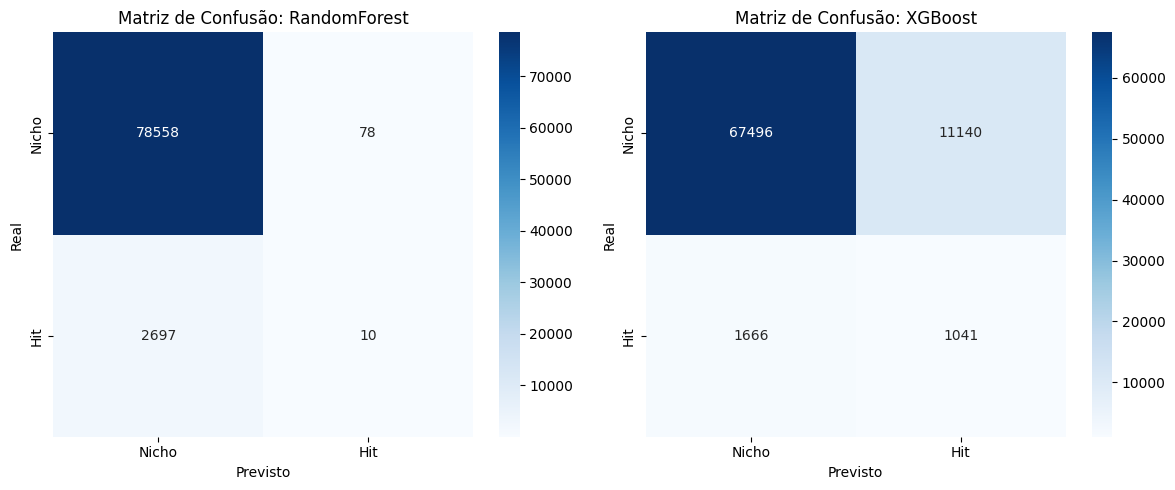

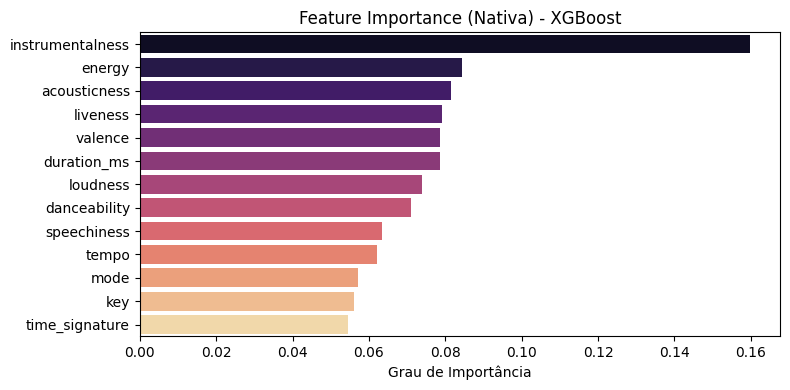


Calculando Valores SHAP para XGBoost...


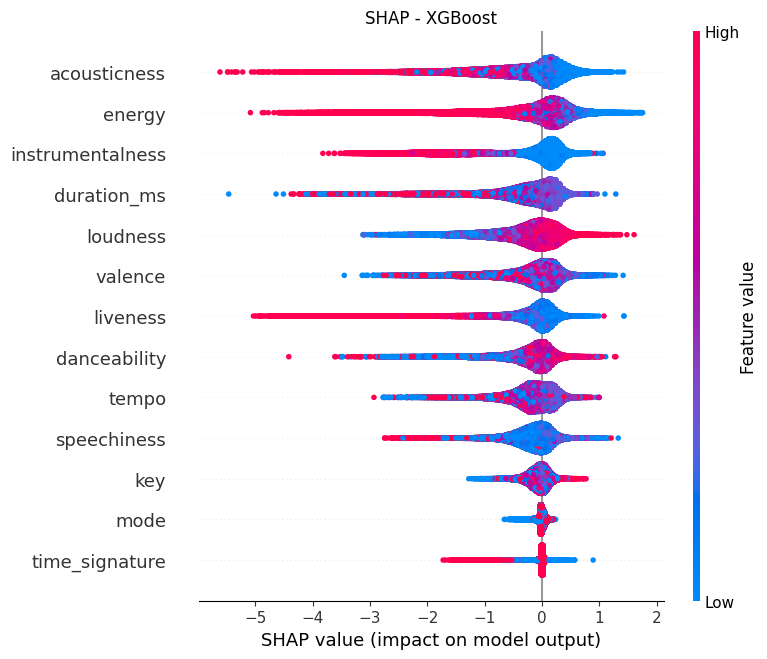

In [12]:
import seaborn as sns

def exibir_matriz_confusao(matrizes: dict, nomes_classes=["Nicho", "Hit"]):
    """
    Plota a Matriz de Confusão consolidada de toda a Validação Cruzada.
    """

    fig, axes = plt.subplots(1, len(matrizes), figsize=(12, 5))
    
    for ax, (nome, matriz) in zip(axes, matrizes.items()):
        sns.heatmap(matrizes[nome], annot=True, fmt='g', cmap='Blues', 
                    xticklabels=nomes_classes, yticklabels=nomes_classes, ax=ax)
        ax.set_title(f"Matriz de Confusão: {nome}")
        ax.set_xlabel('Previsto')
        ax.set_ylabel('Real')
        
    plt.tight_layout()
    plt.savefig("matriz_conf")
    plt.show()

def aplicar_interpretabilidade(modelo_pipeline, X: pd.DataFrame, modelo_nome="XGBoost"):
    """
    Desconstrói a previsão utilizando SHAP e Feature Importance.
    """
    try:
        import shap
    except ImportError:
        print("A biblioteca SHAP não está instalada. Execute: pip install shap")
        return

    scaler = modelo_pipeline.named_steps['scaler']
    clf = modelo_pipeline.named_steps['clf']
    
    X_scaled = scaler.transform(X)
    X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)
    
    # Feature Importance
    if hasattr(clf, 'feature_importances_'):
        plt.figure(figsize=(8, 4))
        importances = clf.feature_importances_
        indices = np.argsort(importances)[::-1]
        sns.barplot(x=importances[indices], y=np.array(X.columns)[indices], palette="magma")
        plt.title(f"Feature Importance (Nativa) - {modelo_nome}")
        plt.xlabel("Grau de Importância")
        plt.tight_layout()
        plt.savefig(f"Feature Importance - {modelo_nome}")
        plt.show()
    
    # SHAP
    print(f"\nCalculando Valores SHAP para {modelo_nome}...")
    explainer = shap.TreeExplainer(clf)
    
    # Amostragem para evitar excesso de uso de memória no plot visual
    # X_amostra = shap.sample(X_scaled_df, 2000) if len(X_scaled_df) > 2000 else X_scaled_df
    shap_values = explainer.shap_values(X_scaled_df)
    
    plt.figure(figsize=(8, 5))
    shap.summary_plot(shap_values, X_scaled_df, show=False)
    plt.title(f"SHAP - {modelo_nome}")
    plt.tight_layout()
    plt.savefig(f"SHAP - {modelo_nome}")
    plt.show()

exibir_matriz_confusao(matrizes)
aplicar_interpretabilidade(modelos_finais['XGBoost'], X, "XGBoost")

## 3.5 Resultados da modelagem final

| modelo | accuracy | precision | recall | f1 | roc_auc | tempo |
|:---:|:---:|:---:|:---:|:---:|---:|---:|
| RandomForest | 0.965885 | 0.0999386 | 0.00369413 | 0.00711657 | 0.723913 | 32.4235 |
| XGBoost | 0.842568 | 0.0854701 | 0.384562 | 0.139846 | 0.734305 | 24.9948 |

<img src="matriz_conf.png">

<img src="Feature Importance - XGBoost.png">

<img src="SHAP - XGBoost.png">

### Interpretação técnica

O RandomForest e o XGBoost foram avaliados sob validação cruzada estratificada. O RandomForest apresentou uma acurácia enganosa de 96,58%, induzido pelo severo desbalanceamento de classes. Sua incapacidade de detectar os verdadeiros sucessos musicais refletiu-se em um Recall quase nulo de 0,0036. Em contrapartida, o XGBoost abriu mão da acurácia global, reduzindo-a para 84,25%, para conseguir identificar os padrões da classe minoritária. O modelo atingiu um Recall maior de 38,45% e um F1-Score de 14%. O uso direto de pesos para a classe positiva também conferiu ao XGBoost maior estabilidade e sensibilidade controlada frente ao desequilíbrio estrutural dos dados.

A qualidade do classificação do Random Forest é inaceitável para o objetivo de negócio, pois ele gera um número altíssimo de falsos negativos. O XGBoost, apesar de ainda registrar um volume grande de falsos positivos, provou ser algoritmo mais viável para capturar os padrões acústicos dos Hits.

A extração da importância global dos atributos revelou que características associadas à energia física da faixa são os principais motores de decisão do XGBoost. Variáveis como volume acústico, energia e nível de acústica lideram os fatores, enquanto métricas temporais e de positividade musical assumem um papel secundário. O aprofundamento por meio dos valores SHAP permitiu mapear a direção desse impacto. Observou-se que níveis elevados de intensidade sonora e energia aumentam a probabilidade de uma música se tornar um sucesso. Por outro lado, índices altos de acústica e presença puramente instrumental reduzem as chances de conversão, evidenciando uma preferência do mercado por músicas mais produzidas.


# 4. Evaluation


## 4.1 Avaliação dos resultados finais


Os resultados obtidos são coerentes com o problema proposto. Prever sucesso comercial apenas a partir de características acústicas é uma tarefa difícil, pois fatores externos como marketing, fama do artista e tendências culturais não estão representados no dataset. Por isso, era esperado que a capacidade preditiva fosse limitada.

As métricas utilizadas foram adequadas para um cenário severamente desbalanceado. A acurácia do Random Forest (96,6%) mostrou-se enganosa, pois o modelo praticamente não identificou a classe "Hit". O XGBoost apresentou menor acurácia, mas maior recall (38,5%) e F1-score (14%), oferecendo uma solução mais compatível com o objetivo de detectar sucessos musicais.

As variáveis mais importantes identificadas pelo XGBoost e pela análise SHAP possuem interpretação plausível. Características relacionadas à energia, intensidade sonora e grau de acústica apresentaram maior influência nas previsões, sugerindo que certos padrões acústicos estão associados ao sucesso comercial.

Não há evidências fortes de overfitting, pois os resultados foram obtidos com validação cruzada estratificada. Entretanto, o desempenho ainda depende do limiar utilizado para definir a variável alvo e do ajuste dos pesos das classes.

As conclusões são sustentadas pelos dados, mas devem ser interpretadas com cautela devido às limitações estruturais do problema.

### Limitações dos resultados

- forte desbalanceamento entre músicas de nicho e hits;
- ausência de variáveis relacionadas a marketing, popularidade histórica e perfil do artista;
- definição arbitrária do limiar de popularidade para criação da variável alvo;
- baixo poder preditivo dos atributos acústicos isolados;
- possibilidade de falsos positivos elevada no XGBoost;
- interpretação limitada por fatores externos não observados.


## 4.2 Comparação final: baseline × guiada × solução final

| Critério | Baseline sugerida pela LLM | Guiada sugerida pela LLM | Solução final implementada | Avaliação crítica |
|---|---|---|---|---|
| Correção técnica | Boa | Muito boa | Muito boa | A solução final incorporou apenas sugestões validadas experimentalmente. |
| Adequação ao problema | Parcial | Boa | Boa | A modelagem foi adaptada ao cenário desbalanceado. |
| Preparação dos dados | Genérica | Mais cuidadosa | Robusta | Remoção de vazamentos e foco em atributos acústicos. |
| Algoritmos escolhidos | Tradicionais | XGBoost e árvores | Random Forest + XGBoost | XGBoost apresentou melhor equilíbrio entre desempenho e interpretabilidade. |
| Métricas de avaliação | Ênfase em acurácia | Inclusão de F1 e ROC-AUC | F1, recall e ROC-AUC | Evitou conclusões baseadas apenas em acurácia. |
| Interpretabilidade | Média | Alta | Alta | Uso de importância de atributos e SHAP. |
| Rastreabilidade | Média | Boa | Boa | Pipeline reproduzível e documentado. |
| Eficiência computacional | Boa | Boa | Boa | Modelos escaláveis e treinamento viável. |
| Aderência às diretrizes | Baixa | Alta | Alta | As diretrizes influenciaram decisões concretas. |


| Critério | Baseline sugerida pela LLM | Guiada sugerida pela LLM | Solução final implementada | Avaliação crítica |
|---|---|---|---|---|
| Correção técnica | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Adequação ao problema | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Preparação dos dados | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Algoritmos escolhidos | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Métricas de avaliação | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Interpretabilidade | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Rastreabilidade | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Eficiência computacional | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |
| Aderência às diretrizes | [ANALISAR] | [ANALISAR] | [ANALISAR] | [COMPARAR] |

### Conclusão da comparação

A baseline apresentou sugestões tecnicamente corretas, porém excessivamente genéricas e pouco sensíveis ao desbalanceamento do problema. A trilha guiada trouxe recomendações mais alinhadas às restrições computacionais, interpretabilidade e riscos de vazamento de dados.

Entretanto, algumas sugestões ainda precisaram ser adaptadas pelo grupo. A solução final incorporou apenas recomendações sustentadas pelos resultados experimentais, tornando-se mais defensível tecnicamente por equilibrar desempenho, interpretabilidade e eficiência.


## 4.3 Sugestões aceitas, rejeitadas e corrigidas


| Sugestão | Origem | Decisão | Justificativa |
|---|---|---|---|
| Utilizar validação cruzada estratificada | Baseline | Aceita | Melhorou a robustez da avaliação. |
| Utilizar XGBoost para tratar classes desbalanceadas | Guiada | Aceita | Obteve melhor recall e F1-score. |
| Utilizar análise SHAP para interpretação | Grupo | Implementada | Permitiu interpretar a influência das variáveis. |

### Erros ou limitações das LLMs

| Erro, omissão ou limitação | Trilha | Impacto potencial | Correção feita pelo grupo |
|---|---|---|---|
| Ênfase excessiva na acurácia | Baseline | Avaliação enganosa | Inclusão de F1, recall e ROC-AUC. |
| Pouca consideração ao desbalanceamento severo | Guiada | Modelo com baixa sensibilidade | Ajuste dos pesos das classes e análise crítica dos resultados. |


## 4.4 Avaliação das diretrizes de IA responsável na solução final

| Diretriz | Como apareceu na Fase 2 | Como foi incorporada na Fase 3 | Evidência no notebook | Limitações |
|---|---|---|---|---|
| Escalabilidade | Priorização de modelos eficientes | Uso de Random Forest e XGBoost | Tempos de execução registrados | Não houve busca exaustiva de hiperparâmetros |
| Usabilidade e interpretabilidade | Preferência por modelos explicáveis | Importância de atributos e SHAP | Gráficos de Feature Importance e SHAP | Explicações continuam limitadas pelos dados disponíveis |

### Discussão crítica

As diretrizes influenciaram não apenas a redação do trabalho, mas também o pipeline técnico. Houve impacto na seleção de atributos, escolha dos algoritmos e interpretação dos resultados.

A preocupação com escalabilidade evitou modelos mais custosos. Já a busca por interpretabilidade motivou a utilização de importância de atributos e SHAP. Em contrapartida, a exclusão de variáveis contextuais reduziu o desempenho potencial do modelo.


## 4.5 Trade-offs finais

| Trade-off | Evidência observada | Decisão final | Justificativa |
|---|---|---|---|
| Desempenho × interpretabilidade | XGBoost é menos transparente que Regressão Logística | Priorizar XGBoost com SHAP | Melhor equilíbrio entre desempenho e explicabilidade |
| Privacidade × utilidade dos dados | Remoção de artistas e identificadores | Manter apenas atributos acústicos | Evitar vazamento e vieses comerciais |
| Eficiência × qualidade dos resultados | Busca limitada de hiperparâmetros | Priorizar custo computacional | Ganhos adicionais seriam modestos |
| Simplicidade × completude da análise | Binarização da popularidade | Manter classificação binária | Simplificou a modelagem e a interpretação |
| Justiça/viés × disponibilidade de atributos | Exclusão de variáveis associadas ao artista | Remover metadados comerciais | Maior neutralidade do modelo |

### Síntese

Os principais trade-offs envolveram desempenho, interpretabilidade e disponibilidade de informação. O grupo optou por uma solução simples, escalável e interpretável, aceitando uma perda de poder preditivo em troca de maior robustez metodológica e menor risco de vieses.


# 5. Conclusão

Neste trabalho, investigamos a possibilidade de prever o sucesso comercial de músicas do Spotify utilizando apenas atributos acústicos. A solução final consistiu em um pipeline de preparação dos dados, remoção de vazamentos, balanceamento implícito via pesos das classes e treinamento de modelos Random Forest e XGBoost.

Os resultados mostraram que a elevada acurácia não representa necessariamente boa capacidade preditiva em problemas desbalanceados. O XGBoost apresentou o melhor desempenho relativo, atingindo maior recall e F1-score, além de permitir interpretação dos fatores mais relevantes por meio de análise de importância e valores SHAP.

As principais limitações estão relacionadas ao forte desbalanceamento da variável alvo e à ausência de fatores externos, como marketing e popularidade dos artistas, que possuem influência significativa no sucesso comercial das músicas.

As LLMs contribuíram principalmente para estruturar o pipeline e sugerir algoritmos e métricas adequadas, mas suas recomendações exigiram validação crítica. A explicitação das diretrizes de IA responsável teve efeito concreto nas decisões de preparação dos dados, interpretabilidade e eficiência computacional.

Como trabalhos futuros, podem ser exploradas técnicas de balanceamento, otimização de hiperparâmetros e incorporação de variáveis contextuais adicionais, buscando aumentar o desempenho sem comprometer a rastreabilidade e a interpretabilidade da solução.


# 6. Checklist final da Fase 3

Antes de entregar, verifique se o notebook contém:

- [x] identificação do grupo;
- [x] link público do dataset;
- [x] validação das restrições mínimas do dataset;
- [x] Business Understanding consolidado;
- [x] descrição clara do dataset;
- [x] dicionário de dados;
- [x] diretrizes de IA responsável escolhidas;
- [x] explicação de como as diretrizes influenciaram a solução final;
- [x] Data Understanding com tabelas, gráficos e interpretação;
- [x] Data Preparation com justificativa das decisões;
- [x] modelagem final executada;
- [x] parâmetros documentados;
- [x] métricas adequadas à tarefa;
- [x] resultados interpretados;
- [x] comparação baseline × guiada × solução final;
- [x] sugestões aceitas, rejeitadas e corrigidas;
- [x] erros e limitações das LLMs;
- [x] trade-offs discutidos;
- [x] conclusão final baseada em evidências;
- [x] referências utilizadas.


# 7. Referências

**Data Mining and Machine Learning: Fundamental Concepts and Algorithms**  
Second Edition  
*Mohammed J. Zaki and Wagner Meira, Jr*  
Cambridge University Press, March 2020  
Disponível em: https://dataminingbook.info/
